       SIMULADOR DE CDB
Aporte inicial: R$ 500
Aporte mensal: R$ 1000
CDI anual (%): 13
CDB (% do CDI): 100
Período (meses): 120
Inflação anual estimada (%): 4,58

Quando o aporte mensal é realizado?
1 - Início do mês
2 - Final do mês
Escolha: 1

       RESULTADO DA SIMULAÇÃO
CDI anual:              13.00%
Rentabilidade do CDB:   100.00% do CDI
Taxa anual do CDB:      13.00%
Taxa mensal equivalente: 1.0237%
----------------------------------------
Total aportado:         R$ 120.500,00
Patrimônio bruto:       R$ 238.008,41
Rendimento bruto:       R$ 117.508,41
----------------------------------------
IMPOSTO DE RENDA POR FAIXA
Até 180 dias         (22.5%): R$ 49,20
181 a 360 dias       (20.0%): R$ 122,11
361 a 720 dias       (17.5%): R$ 436,98
Acima de 720 dias    (15.0%): R$ 17.127,32
----------------------------------------
IR total estimado:      R$ 17.735,62
Rendimento líquido:     R$ 99.772,79
Patrimônio líquido:     R$ 220.272,79
----------------------------------------
Rentabilid

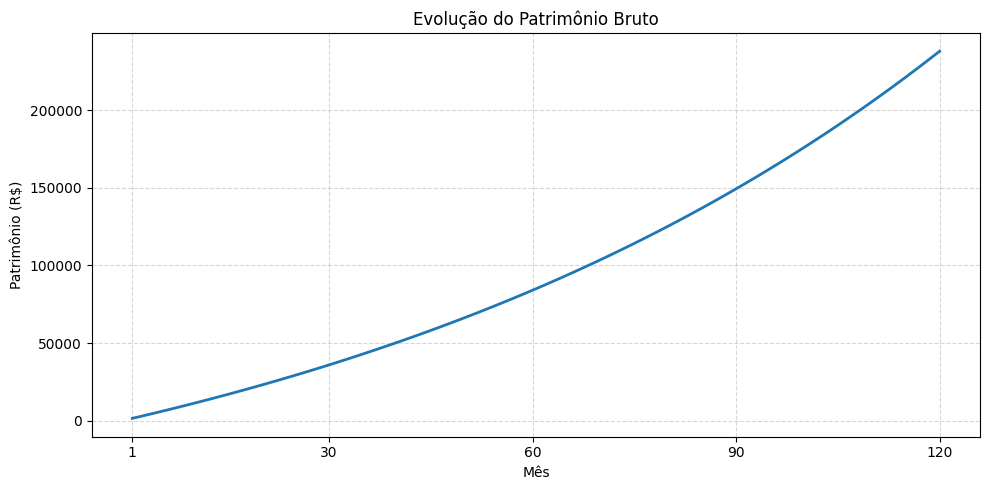

In [7]:

import matplotlib.pyplot as plt


# ========================================
# FUNÇÕES DE ENTRADA
# ========================================

def pedir_numero(mensagem, tipo=float, minimo=0):
    while True:
        try:
            valor = tipo(input(mensagem).replace(",", "."))

            if valor < minimo:
                print(f"Erro: o valor deve ser maior ou igual a {minimo}.")
                continue

            return valor

        except ValueError:
            print("Erro: digite um valor válido.")


def pedir_opcao(mensagem, opcoes):
    while True:
        try:
            valor = int(input(mensagem))

            if valor in opcoes:
                return valor

            print(f"Erro: escolha uma das opções {opcoes}.")

        except ValueError:
            print("Erro: digite uma opção válida.")


def formatar_reais(valor):
    return (
        f"R$ {valor:,.2f}"
        .replace(",", "X")
        .replace(".", ",")
        .replace("X", ".")
    )


# ========================================
# CÁLCULOS FINANCEIROS
# ========================================

def calcular_taxa_cdb(cdi_anual, percentual_cdi):
    # Aproximação: aplica o percentual diretamente
    # à taxa anual informada do CDI.
    return cdi_anual * (percentual_cdi / 100)


def calcular_taxa_mensal(taxa_anual):
    return (1 + taxa_anual / 100) ** (1 / 12) - 1


def calcular_taxa_real(taxa_nominal, inflacao):
    return ((1 + taxa_nominal) / (1 + inflacao)) - 1


def calcular_ir(prazo_dias):
    if prazo_dias <= 180:
        return 0.225
    elif prazo_dias <= 360:
        return 0.20
    elif prazo_dias <= 720:
        return 0.175
    else:
        return 0.15


def obter_faixa_ir(aliquota):
    faixas = {
        0.225: "Até 180 dias",
        0.20: "181 a 360 dias",
        0.175: "361 a 720 dias",
        0.15: "Acima de 720 dias"
    }

    return faixas[aliquota]


# ========================================
# SIMULAÇÃO DO CDB
# ========================================

def simular_cdb(
    aporte_inicial,
    aporte_mensal,
    taxa_mensal,
    meses,
    aporte_inicio
):

    aplicacoes = []

    # Cada aplicação mantém seu próprio saldo,
    # principal e mês de entrada.
    if aporte_inicial > 0:
        aplicacoes.append({
            "principal": aporte_inicial,
            "saldo": aporte_inicial,
            "mes_aporte": 0
        })

    patrimonio_mensal = []

    # ----------------------------------------
    # EVOLUÇÃO DO PATRIMÔNIO
    # ----------------------------------------

    for mes in range(1, meses + 1):

        if aporte_inicio:

            # O novo aporte rende durante o mês.
            if aporte_mensal > 0:
                aplicacoes.append({
                    "principal": aporte_mensal,
                    "saldo": aporte_mensal,
                    "mes_aporte": mes
                })

            for aplicacao in aplicacoes:
                aplicacao["saldo"] *= (1 + taxa_mensal)

        else:

            # Primeiro rendem as aplicações existentes.
            for aplicacao in aplicacoes:
                aplicacao["saldo"] *= (1 + taxa_mensal)

            # O novo aporte entra depois da rentabilidade.
            if aporte_mensal > 0:
                aplicacoes.append({
                    "principal": aporte_mensal,
                    "saldo": aporte_mensal,
                    "mes_aporte": mes
                })

        patrimonio_atual = sum(
            aplicacao["saldo"] for aplicacao in aplicacoes
        )

        patrimonio_mensal.append(patrimonio_atual)

    # ----------------------------------------
    # PATRIMÔNIO BRUTO
    # ----------------------------------------

    total_aportado = sum(
        aplicacao["principal"] for aplicacao in aplicacoes
    )

    patrimonio_bruto = sum(
        aplicacao["saldo"] for aplicacao in aplicacoes
    )

    rendimento_bruto = patrimonio_bruto - total_aportado

    # ----------------------------------------
    # IR POR APLICAÇÃO
    # ----------------------------------------

    imposto_total = 0

    imposto_por_faixa = {
        0.225: 0,
        0.20: 0,
        0.175: 0,
        0.15: 0
    }

    for aplicacao in aplicacoes:

        rendimento = (
            aplicacao["saldo"] - aplicacao["principal"]
        )

        if rendimento <= 0:
            continue

        if aporte_inicio:
            prazo_meses = (
                meses - aplicacao["mes_aporte"] + 1
            )
        else:
            prazo_meses = (
                meses - aplicacao["mes_aporte"]
            )

        # Aproximação: 30 dias por mês.
        prazo_dias = prazo_meses * 30

        aliquota = calcular_ir(prazo_dias)

        imposto_aplicacao = rendimento * aliquota

        imposto_por_faixa[aliquota] += imposto_aplicacao
        imposto_total += imposto_aplicacao

    # ----------------------------------------
    # RESULTADO LÍQUIDO
    # ----------------------------------------

    patrimonio_liquido = patrimonio_bruto - imposto_total

    rendimento_liquido = patrimonio_liquido - total_aportado

    if total_aportado > 0:
        rentabilidade = rendimento_liquido / total_aportado
    else:
        rentabilidade = 0

    return (
        patrimonio_bruto,
        total_aportado,
        rendimento_bruto,
        imposto_total,
        patrimonio_liquido,
        rendimento_liquido,
        rentabilidade,
        patrimonio_mensal,
        imposto_por_faixa
    )


# ========================================
# GRÁFICO
# ========================================

def mostrar_grafico(patrimonio_mensal):

    meses = range(1, len(patrimonio_mensal) + 1)
    total_meses = len(patrimonio_mensal)

    if total_meses <= 12:
        ticks = list(range(1, total_meses + 1))
    else:
        ticks = [1] + list(
            range(30, total_meses + 1, 30)
        )

    plt.figure(figsize=(10, 5))

    plt.plot(
        meses,
        patrimonio_mensal,
        linewidth=2
    )

    plt.title("Evolução do Patrimônio Bruto")
    plt.xlabel("Mês")
    plt.ylabel("Patrimônio (R$)")
    plt.xticks(ticks)

    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# ========================================
# PROGRAMA PRINCIPAL
# ========================================

print("=" * 40)
print("       SIMULADOR DE CDB")
print("=" * 40)

aporte_inicial = pedir_numero("Aporte inicial: R$ ")
aporte_mensal = pedir_numero("Aporte mensal: R$ ")
cdi_anual = pedir_numero("CDI anual (%): ")
percentual_cdi = pedir_numero("CDB (% do CDI): ")
meses = pedir_numero("Período (meses): ", int, 1)
inflacao_anual = pedir_numero(
    "Inflação anual estimada (%): "
)

opcao_aporte = pedir_opcao(
    "\nQuando o aporte mensal é realizado?\n"
    "1 - Início do mês\n"
    "2 - Final do mês\n"
    "Escolha: ",
    [1, 2]
)

# ----------------------------------------
# TAXAS
# ----------------------------------------

taxa_cdb_anual = calcular_taxa_cdb(
    cdi_anual,
    percentual_cdi
)

taxa_mensal = calcular_taxa_mensal(taxa_cdb_anual)

taxa_real = calcular_taxa_real(
    taxa_cdb_anual / 100,
    inflacao_anual / 100
)

aporte_inicio = opcao_aporte == 1

# ----------------------------------------
# SIMULAÇÃO
# ----------------------------------------

(
    patrimonio_bruto,
    total_aportado,
    rendimento_bruto,
    imposto_total,
    patrimonio_liquido,
    rendimento_liquido,
    rentabilidade,
    patrimonio_mensal,
    imposto_por_faixa
) = simular_cdb(
    aporte_inicial,
    aporte_mensal,
    taxa_mensal,
    meses,
    aporte_inicio
)

# ----------------------------------------
# INFLAÇÃO ACUMULADA
# ----------------------------------------

inflacao_mensal = calcular_taxa_mensal(inflacao_anual)

fator_inflacao = (1 + inflacao_mensal) ** meses

patrimonio_real = patrimonio_liquido / fator_inflacao

# ========================================
# RESULTADO
# ========================================

print("\n" + "=" * 40)
print("       RESULTADO DA SIMULAÇÃO")
print("=" * 40)

print(f"CDI anual:              {cdi_anual:.2f}%")
print(f"Rentabilidade do CDB:   {percentual_cdi:.2f}% do CDI")
print(f"Taxa anual do CDB:      {taxa_cdb_anual:.2f}%")
print(f"Taxa mensal equivalente: {taxa_mensal * 100:.4f}%")

print("-" * 40)

print(f"Total aportado:         {formatar_reais(total_aportado)}")
print(f"Patrimônio bruto:       {formatar_reais(patrimonio_bruto)}")
print(f"Rendimento bruto:       {formatar_reais(rendimento_bruto)}")

print("-" * 40)
print("IMPOSTO DE RENDA POR FAIXA")

for aliquota in [0.225, 0.20, 0.175, 0.15]:
    descricao = obter_faixa_ir(aliquota)
    imposto_faixa = imposto_por_faixa[aliquota]

    print(
        f"{descricao:20} ({aliquota * 100:4.1f}%): "
        f"{formatar_reais(imposto_faixa)}"
    )

print("-" * 40)

print(f"IR total estimado:      {formatar_reais(imposto_total)}")
print(f"Rendimento líquido:     {formatar_reais(rendimento_liquido)}")
print(f"Patrimônio líquido:     {formatar_reais(patrimonio_liquido)}")

print("-" * 40)

print(f"Rentabilidade simples:  {rentabilidade * 100:.2f}%")
print(f"Taxa real anual bruta:  {taxa_real * 100:.2f}%")

print("-" * 40)

print(
    f"Patrimônio em valores de hoje: "
    f"{formatar_reais(patrimonio_real)}"
)

print("=" * 40)

mostrar_grafico(patrimonio_mensal)

